# 02-MuJoCo入门：Hello World与方块下落仿真


## 1. 本课目标：让方块掉下去

本篇对应《具身智能机器人实战》第 02 节，原课件标题为 **《Mujoco Hello world》**，副标题是“让方块掉下去”，配套视频名为《02_mujoco入门》。

上一节建立了“加载模型、设定状态、推进仿真”的整体认识，本节用一个悬空方块验证最基本的物理过程：设置地板、方块和重力，让 MuJoCo 算出方块下落的运动。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/02_mujoco helloworld.pptx` 全部 6 页，其中第 6 页为品牌结束页。正文顺序跟随第 1～5 页，图注标明原课件页码。

课件给出了环境搭建命令和 `python demo.py` 的运行入口，没有展示 `demo.py` 源码。本篇未转录配套视频、未读取 `code.zip`，因此将命令修正、uv 环境操作和可复现的最小示例标为“工程补充”，不把它们当成课程原始源码。


## 2. 为什么先测试一个方块

课件先提醒：入门时直接让人形机器人做复杂动作，会同时遇到模型、关节、平衡和控制等问题，难以判断失败发生在哪一步。

方块下落只需要一个简单场景，便于检查物理引擎是否能够正常工作。只要方块具有可运动的自由度，并在重力作用下随仿真时间下落，就能先确认模型描述和物理计算的基本流程已经接通。

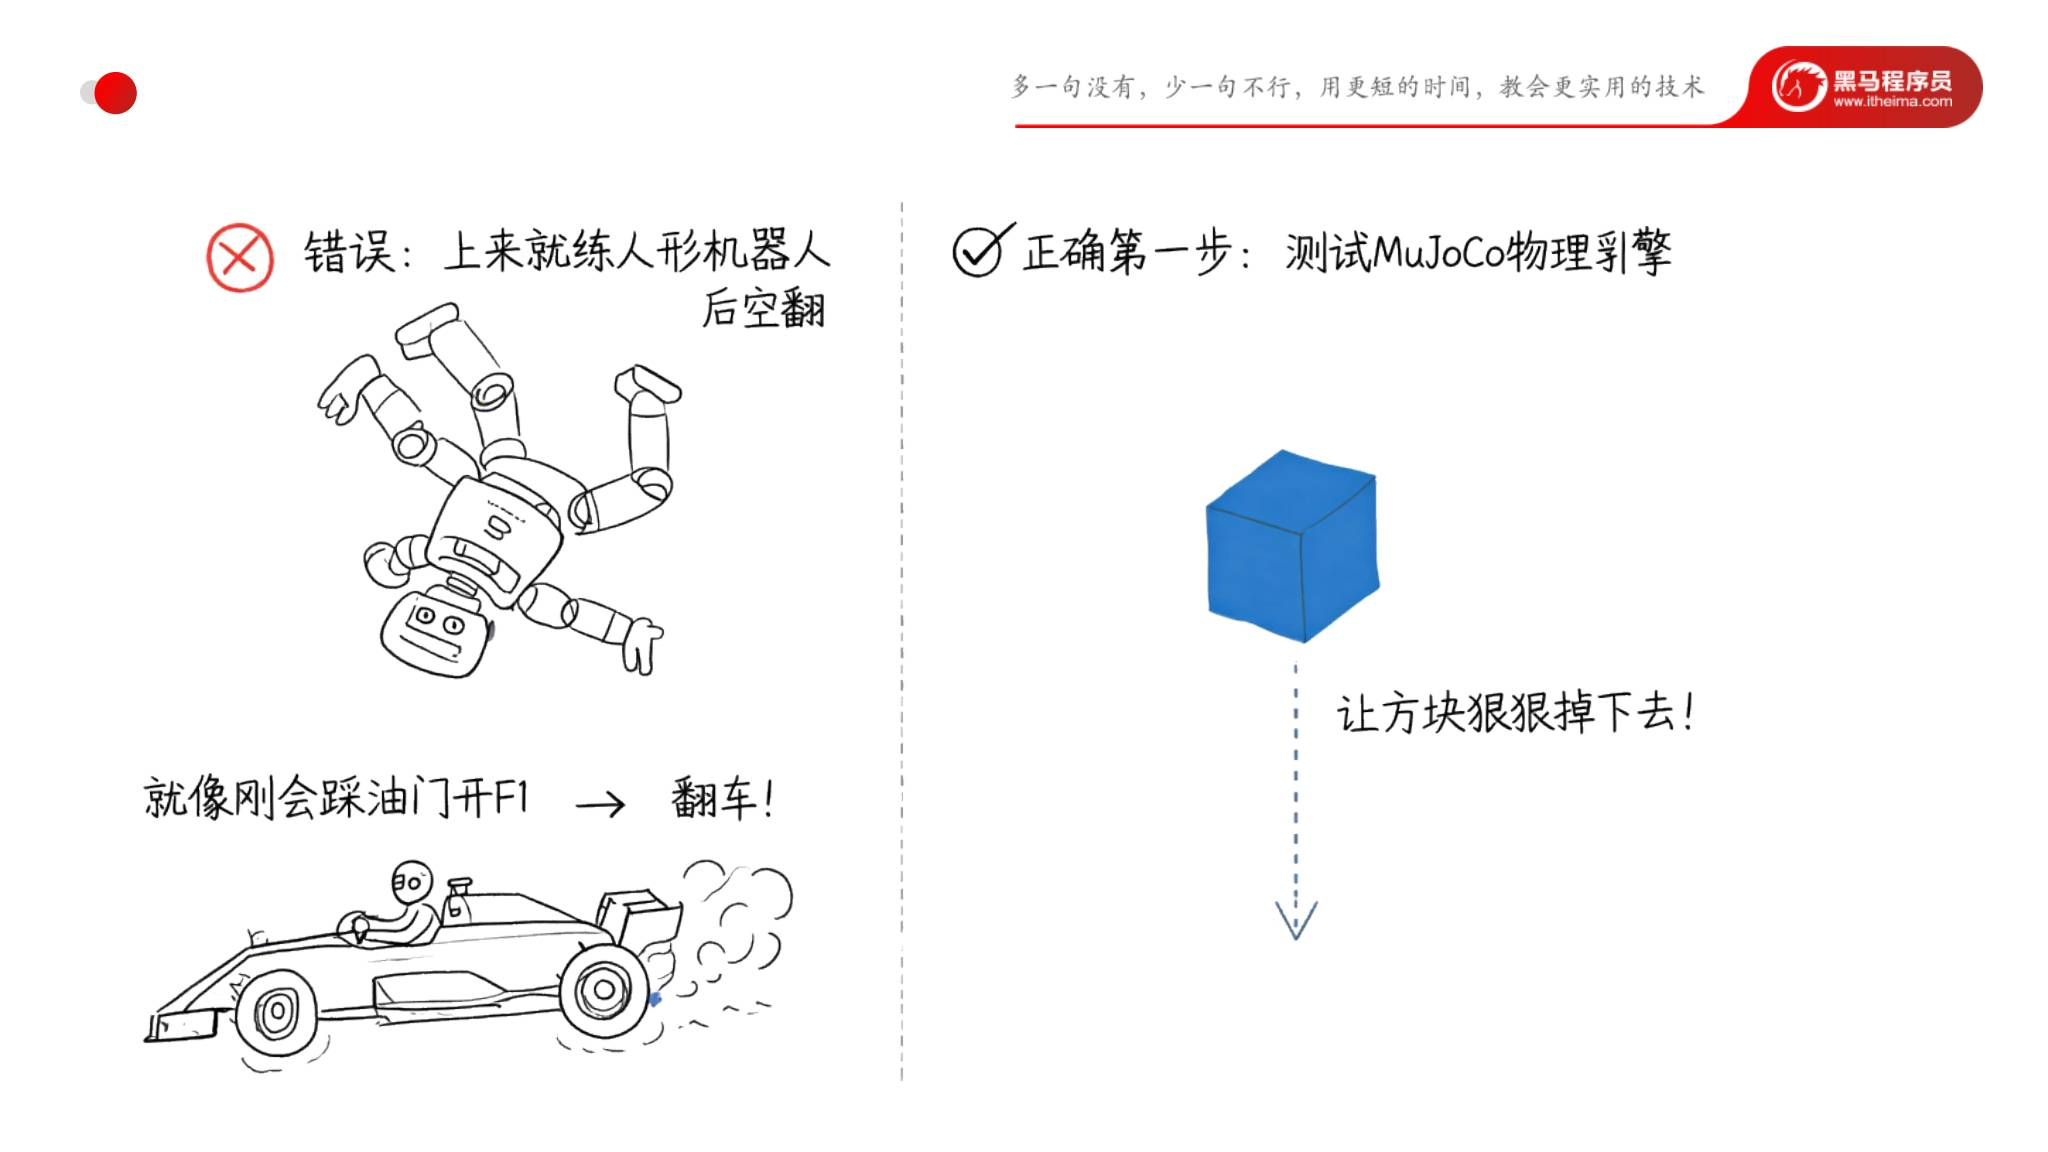

*原课件第 2 页：先完成简单的物理引擎测试，再进入复杂机器人动作。*

本节的预期现象很具体：方块从地板上方开始下落，随后与地板接触。看到这个过程，才有基础继续加载下一节的 T800 模型。


## 3. MuJoCo 在计算什么

课件把 MuJoCo 比作“物理世界计算器”。使用时先提供场景和物理条件，再让引擎根据力学关系计算下一时刻的运动。

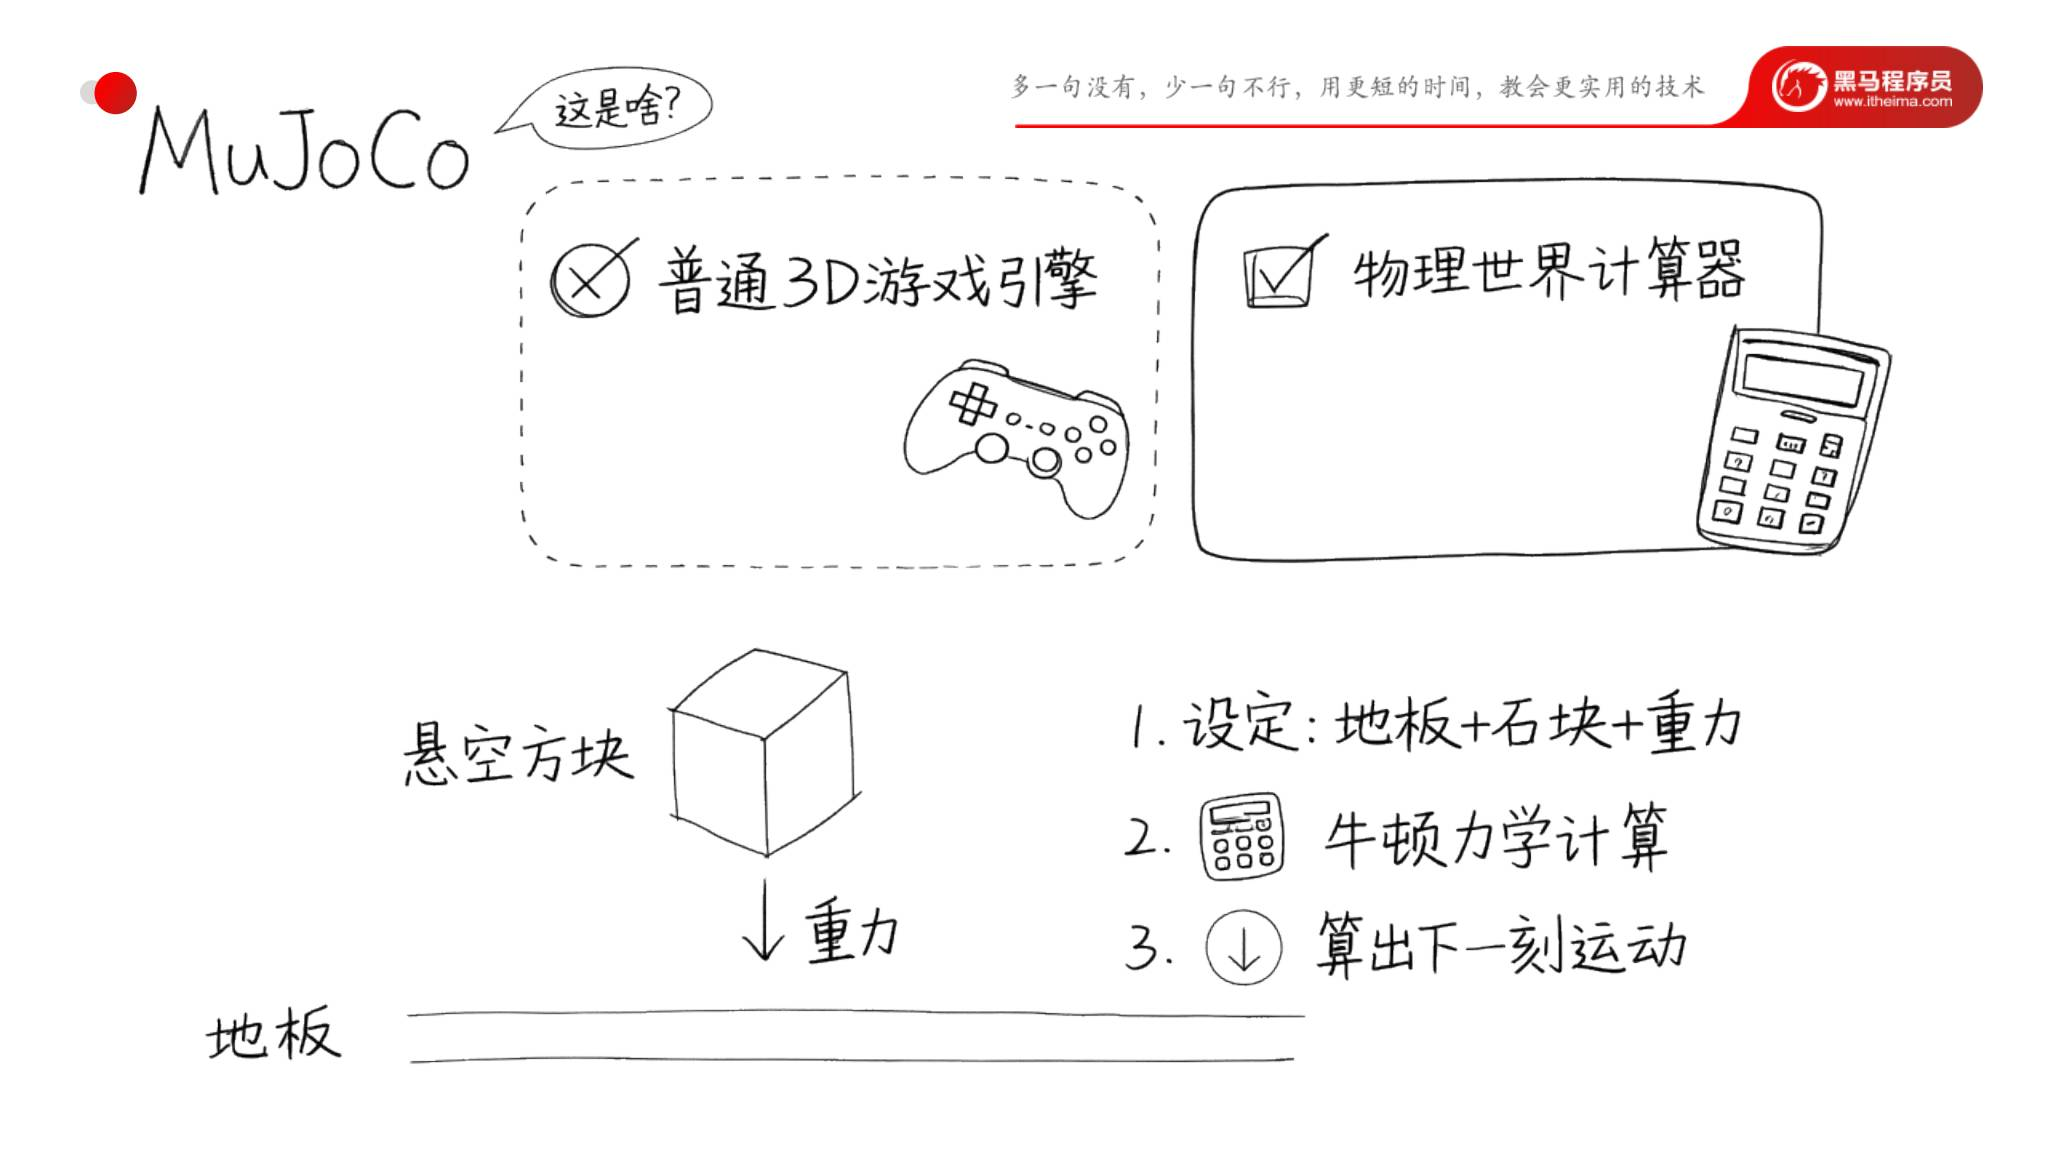

*原课件第 3 页：设置地板、方块和重力，然后计算后续运动。*

| 组成部分 | 在本节中的作用 |
|---|---|
| 地板 | 为方块提供碰撞和接触的表面 |
| 方块 | 作为能够运动的仿真对象 |
| 重力 | 使悬空方块向下加速 |
| 物理步进 | 根据当前状态计算下一步状态 |

因此，除了在窗口中画出一个方块，还要让物理计算真正推进。若只创建场景而不推进时间，就无法观察到下落过程。


## 4. 课程的安装步骤与命令修正

第 4 页用 `pip install mujoco` 和 `python demo.py` 说明基本用法，第 5 页进一步给出了 Python 环境和依赖版本。

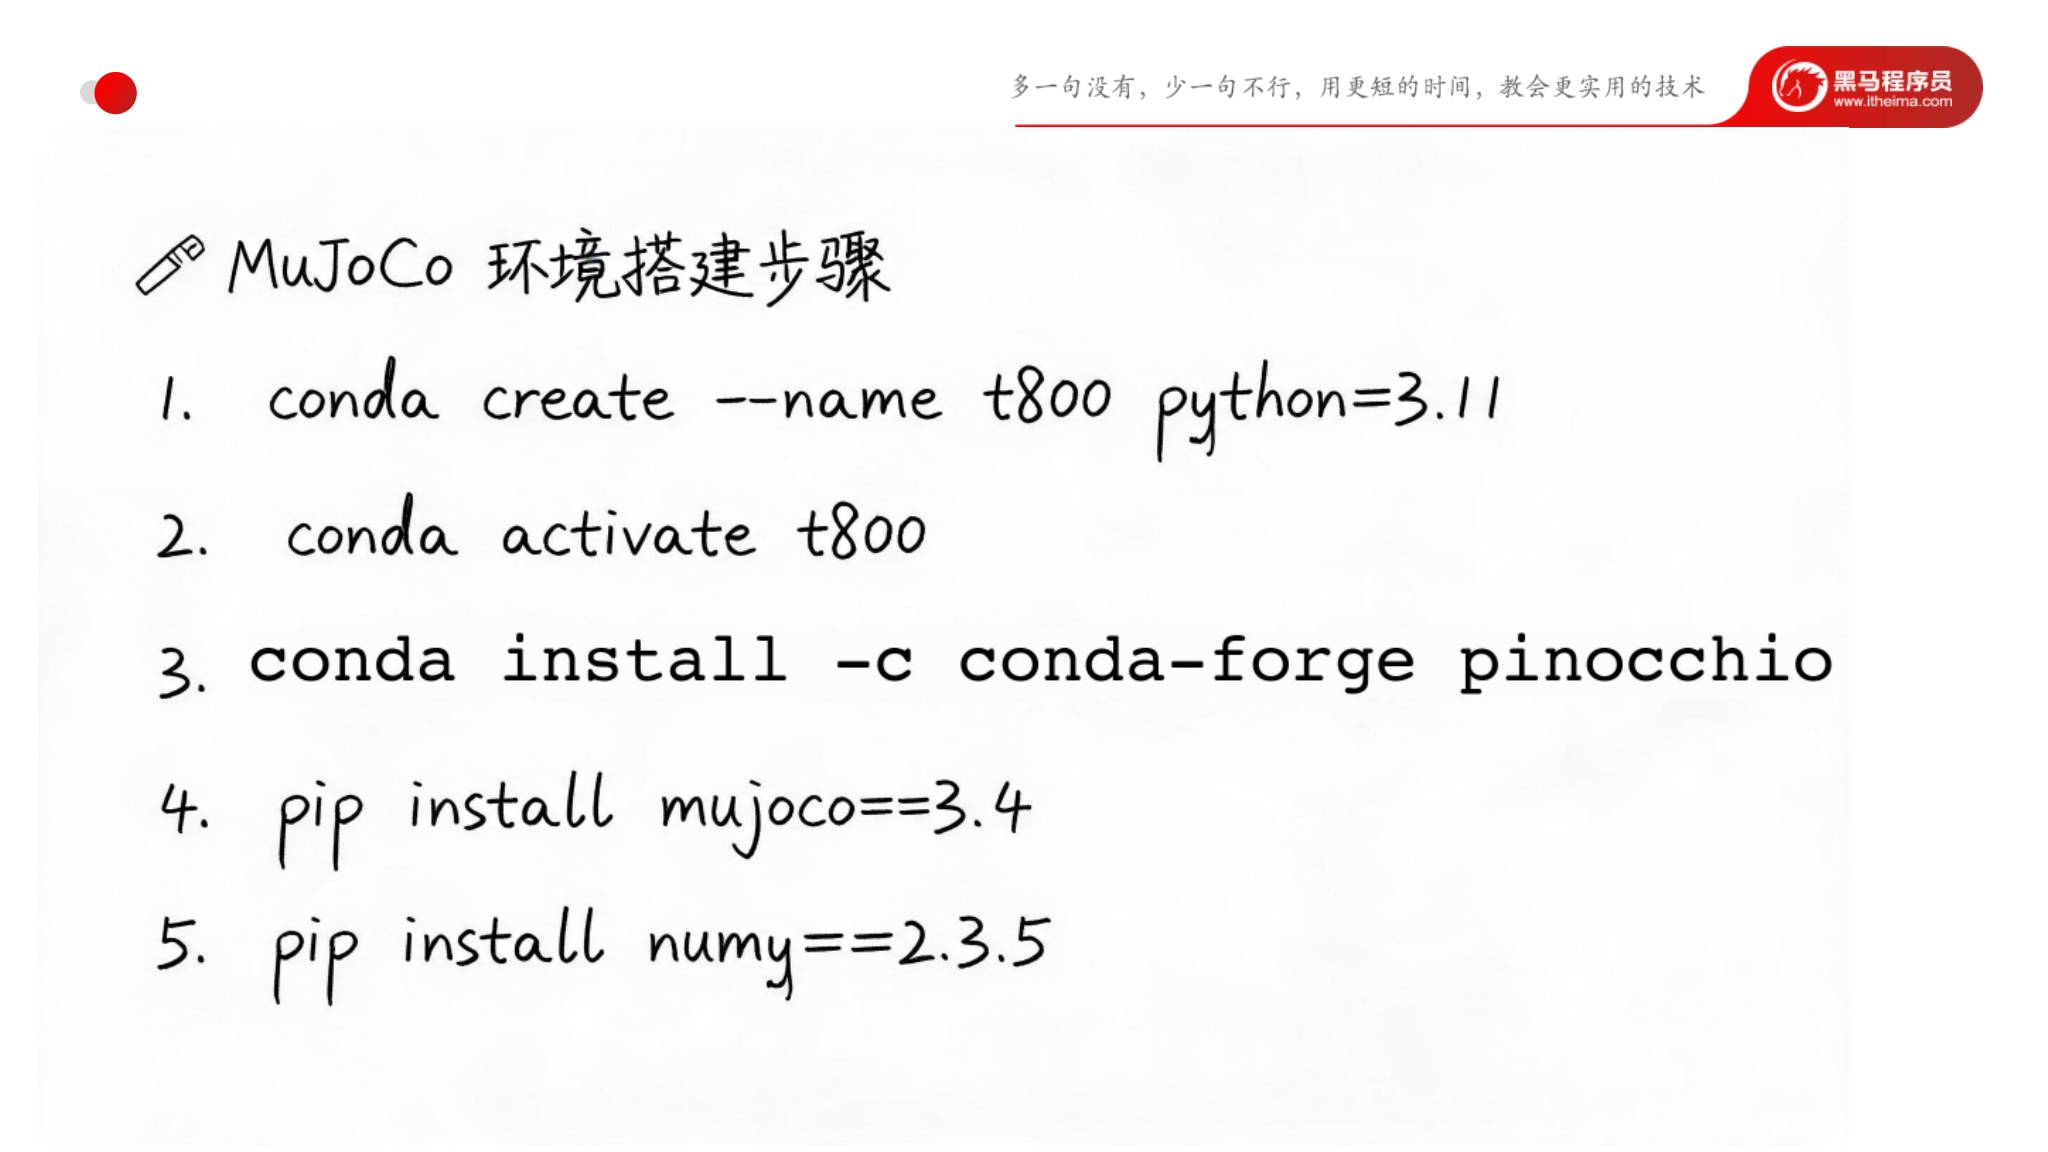

*原课件第 5 页：使用名为 t800 的 Python 3.11 环境，安装 Pinocchio、MuJoCo 和 NumPy。图中部分安装语法、包名需要按下文修正。*

### 4.1 课件原命令

以下保留课件的五步写法，**作为原文对照，包含需要修正的内容**：

```text
conda create --name t800 python=3.11
conda activate t800
conda install -c conda-forge pinocchio
pip install mujoco=3.4
pip install numy==2.3.5
```

顺序含义是：先创建并进入专用环境，再安装依赖，让后续脚本使用这套环境中的 Python 和库。

### 4.2 工程补充：两处修正与依赖范围

| 课件写法 | 整理后的写法或说明 |
|---|---|
| `python=3.11` | 这是 Conda 的版本约束写法，保留 |
| `pip install mujoco=3.4` | pip 固定版本使用 `==`，本篇写为 `python -m pip install mujoco==3.4.0` |
| `pip install numy==2.3.5` | 这里应为 NumPy，写为 `python -m pip install numpy==2.3.5` |
| `conda install -c conda-forge pinocchio` | 是课件列出的依赖，保留；下面的独立方块示例仅需 MuJoCo，无需导入 Pinocchio |

PyPI 的版本信息确认存在 `mujoco==3.4.0` 和 `numpy==2.3.5`，两者均提供 Windows x64、CPython 3.11 的安装包。不要因为第 4 页使用了通用安装命令，就忽略第 5 页对课程版本的进一步约定。

如果已经按课程创建并激活 `t800` Conda 环境，可按原顺序安装 Pinocchio，再执行上表修正后的两条 pip 命令。`python -m pip` 能明确使用当前 Python 对应的 pip。


## 5. 工程补充：使用 uv 准备本节练习环境

这里沿用笔记项目使用 uv 的习惯，为本节的独立方块练习创建 Python 3.11 环境。它对应课件的环境隔离目的，使用 `.venv` 目录替代名为 `t800` 的 Conda 环境。

以下为 **Windows PowerShell** 操作。先在自行选择的练习父目录中打开终端，再创建并进入练习目录。需要事先能够运行 `uv`。

```powershell
mkdir mujoco-hello
Set-Location mujoco-hello
uv venv --python 3.11 .venv
uv pip install --python .\.venv\Scripts\python.exe "mujoco==3.4.0" "numpy==2.3.5"
```

uv 在缺少对应解释器时可能需要联网下载 Python。后续始终使用 `.venv` 中的解释器，无需激活环境，也能避免装包与运行脚本使用不同的 Python。

仍在 `mujoco-hello` 目录中，检查安装版本：

```powershell
.\.venv\Scripts\python.exe -c "import sys, mujoco, numpy; print(sys.version); print('MuJoCo:', mujoco.__version__); print('NumPy:', numpy.__version__)"
```

应能成功导入，并显示 Python 3.11 系列、MuJoCo `3.4.0` 和 NumPy `2.3.5`。这一步验证导入和版本，图形窗口是否能够打开还要通过后面的查看器检查。

该独立练习没有迁移课件中的 Pinocchio 依赖。若使用完整课程源码，应以源码实际导入和依赖要求为准，不能把这里的最小依赖当成整个 T800 项目的依赖清单。


## 6. 工程补充：最小方块下落实例

课件只给出 `python demo.py`，没有提供该脚本正文。下面按“地板、方块、重力”的原课目标补充一个最小实现，用于复现同类现象，**不代表课程原始 `demo.py`**。

### 6.1 创建场景文件 scene.xml

在上一步的 `mujoco-hello` 目录中新建 `scene.xml`，内容如下。这个文件使用 MuJoCo 的 MJCF XML 格式描述场景。

```xml
<mujoco model="falling_box">
  <option timestep="0.002" gravity="0 0 -9.81"/>

  <worldbody>
    <light pos="0 0 3" dir="0 0 -1"/>
    <geom name="floor" type="plane" size="2 2 0.1"
          rgba="0.8 0.8 0.8 1"/>

    <body name="box" pos="0 0 1">
      <freejoint/>
      <geom name="box_geom" type="box" size="0.1 0.1 0.1"
            mass="1" rgba="0.1 0.4 0.9 1"/>
    </body>
  </worldbody>
</mujoco>
```

几个会直接影响现象的设置：

| 配置 | 含义 |
|---|---|
| `gravity="0 0 -9.81"` | 重力加速度沿负 z 轴，单位为米每二次方秒 |
| `timestep="0.002"` | 每次物理步进推进 0.002 秒仿真时间 |
| `type="plane"` | 创建位于世界原点、朝向默认 z 方向的地板平面 |
| `pos="0 0 1"` | 使方块初始中心位于地板上方 1 米 |
| `<freejoint/>` | 允许方块自由平移和旋转；若没有关节，刚体会固定在父体上 |
| 方块的 `size="0.1 0.1 0.1"` | 表示三个方向的半尺寸，因此完整边长为 0.2 米 |
| `mass="1"` | 方块质量为 1 千克 |

方块接触地面并稳定后，中心高度应接近 0.1 米，而不是 0 米，因为方块本身有厚度。接触求解可能产生微小穿入或短暂振动。

### 6.2 创建运行脚本 demo.py

在同一目录中新建 `demo.py`：

```python
import time
from pathlib import Path

import mujoco
import mujoco.viewer


def main():
    scene_path = Path(__file__).resolve().with_name("scene.xml")
    model = mujoco.MjModel.from_xml_path(str(scene_path))
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)

    with mujoco.viewer.launch_passive(model, data) as viewer:
        while viewer.is_running():
            step_start = time.perf_counter()
            mujoco.mj_step(model, data)
            viewer.sync()

            remaining = model.opt.timestep - (time.perf_counter() - step_start)
            if remaining > 0:
                time.sleep(remaining)


if __name__ == "__main__":
    main()
```

这段程序对应上一节介绍的数据流：

1. `MjModel.from_xml_path()` 读取并编译场景描述，得到模型。
2. `MjData(model)` 创建该模型对应的仿真数据。
3. `mj_forward()` 在初始状态下更新派生量，不推进仿真时间。
4. `mj_step()` 推进物理计算，方块位置、速度等状态随之更新。
5. `viewer.sync()` 将更新后的状态同步到查看器。

`launch_passive()` 让脚本负责步进过程。`time.sleep()` 用来粗略控制演示速度，不能保证严格实时。XML 路径基于脚本自身位置构造，避免从其他目录运行时找错文件。

### 6.3 运行并观察

仍在练习目录中执行：

```powershell
.\.venv\Scripts\python.exe demo.py
```

预期打开查看器，看到蓝色方块从上方落向灰色地板，并在接触后逐渐稳定。关闭窗口后循环结束。下落过程较短，方块很快落地属于正常现象。

也可以直接让 MuJoCo 自带查看器加载同一场景：

```powershell
.\.venv\Scripts\python.exe -m mujoco.viewer --mjcf=scene.xml
```

此入口由查看器管理仿真循环。如果场景处于暂停状态，可按空格切换运行。


## 7. 工程补充：确认下落和接触确实发生

看到方块并不等于已经推进物理计算。为了把检查落到状态数据上，可以创建 `check_fall.py`，在不打开窗口的情况下验证同一个 `scene.xml`：

```python
from pathlib import Path

import mujoco


scene_path = Path(__file__).resolve().with_name("scene.xml")
model = mujoco.MjModel.from_xml_path(str(scene_path))
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

start_z = float(data.body("box").xpos[2])
while data.time < 0.2:
    mujoco.mj_step(model, data)
mujoco.mj_forward(model, data)
fall_z = float(data.body("box").xpos[2])
assert fall_z < start_z, "方块没有下落"
assert data.ncon == 0, "此时方块应仍处于接触前的下落阶段"

while data.time < 2.0:
    mujoco.mj_step(model, data)
mujoco.mj_forward(model, data)
rest_z = float(data.body("box").xpos[2])
assert abs(rest_z - 0.1) < 0.02, "方块没有在地板附近稳定"
assert data.ncon > 0, "未检测到方块与地板接触"

print(f"初始高度：{start_z:.3f} m")
print(f"下落中高度：{fall_z:.3f} m")
print(f"落地后高度：{rest_z:.3f} m")
print("方块下落与地板接触检查通过")
```

在练习目录执行：

```powershell
.\.venv\Scripts\python.exe check_fall.py
```

这个检查验证的是补充场景的物理计算，断言范围只适用于这里约定的初始高度和尺寸。`mj_forward()` 让读取的世界坐标与当前状态保持一致。无窗口检查通过后，如果图形入口仍报错，应继续排查查看器和图形环境。

| 现象 | 优先检查的位置 |
|---|---|
| `import mujoco` 失败 | 是否安装到了运行脚本所用的 `.venv` |
| 找不到 `scene.xml` | XML 是否与两个脚本放在同一目录，是否误保存成 `.xml.txt` |
| 方块始终悬空 | 是否保留 `<freejoint/>`、启用重力并调用了 `mj_step()` |
| 状态在变化但画面不动 | 被动查看器循环是否调用 `viewer.sync()` |
| 方块穿过地面 | 是否保留地板几何体，是否修改了碰撞相关设置 |
| 检查脚本通过，但窗口打不开 | 查看器报错和本机 OpenGL、显示环境是否正常 |


## 8. 本课完成标准与补充参考

原课的第一个练习是让方块掉下去。完成时，应能够解释重力为什么使方块运动，并把“创建场景、准备环境、运行脚本、观察下落”连成一套操作。

本篇补充示例已在 Python 3.11、MuJoCo 3.4.0、NumPy 2.3.5 的独立环境中完成无窗口检查，验证了方块下落和地板接触。查看器代码经过语法检查，本次未打开图形窗口，也未执行 T800 模型或真实硬件控制。

用于核对补充接口和安装版本的参考：

- [MuJoCo 3.4.0 Python 文档](https://mujoco.readthedocs.io/en/3.4.0/python.html)：安装、模型加载与查看器用法。
- [MuJoCo 3.4.0 XML 参考](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html)：时间步长、重力、自由关节与几何体尺寸。
- [MuJoCo 3.4.0 安装包信息](https://pypi.org/project/mujoco/3.4.0/)和 [NumPy 2.3.5 安装包信息](https://pypi.org/project/numpy/2.3.5/)：版本和 Python 兼容信息。

下一节是“加载 T800”，将把这里的简单对象换成课程机器人模型。
